## Pratical 1

In [2]:
from google.colab import drive

drive.mount('/content/drive/')

Mounted at /content/drive/


In [27]:
import os
import csv
from collections import Counter
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import random
import pandas as pd
import numpy as np


In [28]:
!ls '/content/drive/MyDrive/ml-latest-small'

links.csv  movies.csv  ratings.csv  README.txt	tags.csv


In [29]:
DATAFILE = '/content/drive/MyDrive/ml-latest-small/ratings.csv'

In [30]:
class Ratings:
  def __init__(self, datafile_name):
    self.datafile_name = datafile_name
    self.length = self._compute_length()

    self.user_to_index = {}
    self.item_to_index = {}

    self.user_data = []
    self.item_data = []

    self.index_to_user = []
    self.index_to_item = []

    self.n_users = 0
    self.n_items = 0

  def build_matrix(self):
    self._create_sets()
    self._create_indexs()

    self.data_by_user = [[] for _ in range(self.n_users)]
    self.data_by_item = [[] for _ in range(self.n_items)]

    with open(self.datafile_name, 'r') as file:
      reader = csv.reader(file)
      next(reader)

      for user_id, item_id, rating, _ in tqdm(reader, total=self.length):
        user_index = self._user_index(user_id)
        item_index = self._item_index(item_id)
        rating = float(rating)

        self.data_by_user[user_index].append(
            (item_index, rating)
        )
        self.data_by_item[item_index].append(
            (user_index, rating)
        )

  def _compute_length(self):
    with open(self.datafile_name, 'r') as file:
      reader = csv.reader(file)
      next(reader)
      return sum(1 for _ in reader)

  def _create_sets(self):
    self.user_set, self.item_set = set(), set()

    with open(self.datafile_name, 'r') as file:
      reader = csv.reader(file)
      next(reader)
      for row in tqdm(reader, total=self.length):
        self.user_set.add(row[0])
        self.item_set.add(row[1])
    self.index_to_user = sorted(list(self.user_set))
    self.index_to_item = sorted(list(self.item_set))
    self.n_users = len(self.index_to_user)
    self.n_items = len(self.index_to_item)

  def _create_indexs(self):
    for i, user in tqdm(enumerate(self.index_to_user), total=self.n_users):
      self.user_to_index[user] = i
    for i, item in tqdm(enumerate(self.index_to_item), total=self.n_items):
      self.item_to_index[item] = i

  def _user_index(self, user_id):
    return self.user_to_index[user_id]

  def _item_index(self, item_id):
    return self.item_to_index[item_id]

  def _n_user(self):
    return len(self.index_to_user)

  def _n_item(self):
    return len(self.index_to_item)

  def _compute_frequencies(self):
    user_degrees = [len(user_ratings) for user_ratings in self.data_by_user]
    item_degrees = [len(item_ratings) for item_ratings in self.data_by_item]

    self.user_counts = Counter(user_degrees)
    self.item_counts = Counter(item_degrees)

    self.user_frequencies = sorted(self.user_counts.keys())
    self.item_frequencies = sorted(self.item_counts.keys())

  def plot_distributions(self):
    self._compute_frequencies()

    users_y = [self.user_counts[d] for d in self.user_frequencies]
    items_y = [self.item_counts[d] for d in self.item_frequencies]

    plt.figure()

    plt.scatter(self.user_frequencies, users_y, s=8, label='users')
    plt.scatter(self.item_frequencies, items_y, s=8, label='items')

    plt.xscale("log")
    plt.yscale("log")

    plt.xlabel("degree")
    plt.ylabel("frequency")
    plt.title("MovieLens degree distributions")

    plt.legend()
    plt.show()

  def train_test_split(self, test_fraction=0.1):
    if self.n_users == 0:
      self.build_matrix()

    data_by_user_train  = [[] for _ in range(self.n_users)]
    data_by_user_test   = [[] for _ in range(self.n_users)]
    data_by_item_train = [[] for _ in range(self.n_items)]
    data_by_item_test  = [[] for _ in range(self.n_items)]

    for user_index, ratings in tqdm(enumerate(self.data_by_user), total=self.n_users):
        ratings_shuffled = ratings.copy()
        random.shuffle(ratings_shuffled)
        n_test = int(len(ratings_shuffled) * test_fraction)
        split_point = len(ratings_shuffled) - n_test

        for i, (item_index, rating) in enumerate(ratings_shuffled):
            rating = float(rating)
            if i < split_point:
                data_by_user_train[user_index].append((item_index, rating))
                data_by_item_train[item_index].append((user_index, rating))
            else:
                data_by_user_test[user_index].append((item_index, rating))
                data_by_item_test[item_index].append((user_index, rating))

    return (data_by_user_train, data_by_user_test), (data_by_item_train, data_by_item_test)


In [31]:
ratings = Ratings(DATAFILE)
ratings.length

100836

In [32]:
ratings.build_matrix()

  0%|          | 0/100836 [00:00<?, ?it/s]

  0%|          | 0/610 [00:00<?, ?it/s]

  0%|          | 0/9724 [00:00<?, ?it/s]

  0%|          | 0/100836 [00:00<?, ?it/s]

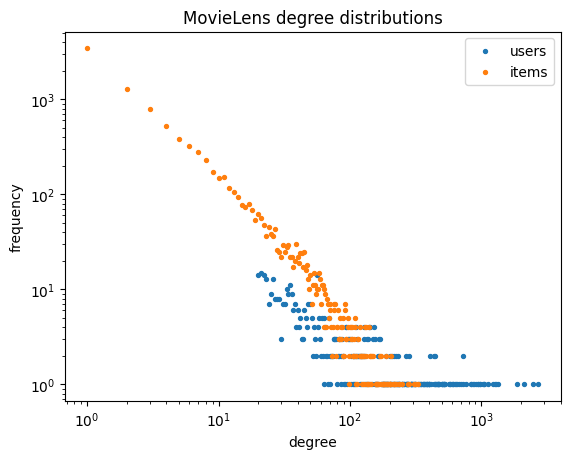

In [33]:
ratings.plot_distributions()

## Pratical 2

In [34]:
users_data, items_data = ratings.train_test_split()

  0%|          | 0/610 [00:00<?, ?it/s]

In [35]:
data_by_user_train, data_by_user_test = users_data
data_by_item_train, data_by_item_test = items_data

In [36]:
def to_arrays(data_by_x):
  idx = [np.array([a for a, _ in lst], dtype=int) for lst in data_by_x]
  val = [np.array([r for _, r in lst], dtype=float) for lst in data_by_x]
  return idx, val

user_items_train, user_ratings_train = to_arrays(data_by_user_train)
user_items_test, user_ratings_test = to_arrays(data_by_user_test)
item_users_train, item_ratings_train = to_arrays(data_by_item_train)
item_users_test, item_rating_test = to_arrays(data_by_item_test)

In [37]:
def squared_error(user_items, user_ratings, user_biases, item_biases):
  se, count = 0.0, 0
  for m in range(ratings.n_users):
    items, r = user_items[m], user_ratings[m]
    if len(items) == 0:
      continue
    pred = user_biases[m] + item_biases[items]
    se += np.sum((r - pred) ** 2)
    count += len(items)
  return se, count

def loss_fn(user_items, user_ratings, user_biases, item_biases, lbda, gamma):
  se, _ = squared_error(user_items, user_ratings, user_biases, item_biases)
  loss = (lbda / 2 * se + gamma / 2 * (np.sum(user_biases ** 2) + np.sum(item_biases ** 2)))
  return loss

def rmse(user_items, user_ratings, user_biases, item_biases):
    se, count = squared_error(user_items, user_ratings, user_biases, item_biases)
    return np.sqrt(se / count)

In [38]:
def update_user_biases(user_items, user_ratings, user_biases, item_biases, lbda, gamma):
  for m in range(ratings.n_users):
    items, r = user_items[m], user_ratings[m]
    if len(items) == 0:
      continue
    total = np.sum(r - item_biases[items])
    user_biases[m] = lbda * total / (lbda * len(items) + gamma)

def update_item_biases(item_users, item_ratings, user_biases, item_biases, lbda, gamma):
  for n in range(ratings.n_items):
    users, r = item_users[n], item_ratings[n]
    if len(users) == 0:
      continue
    total = np.sum(r - user_biases[users])
    item_biases[n] = lbda * total / (lbda * len(users) + gamma)


lbda, gamma = 1.0, 0.1
user_biases = np.zeros(ratings.n_users)
item_biases = np.zeros(ratings.n_items)

losses, train_rmse, test_rmse = [], [], []

for i in tqdm(range(10)):
  update_user_biases(
      user_items=user_items_train,
      user_ratings=user_ratings_train,
      user_biases=user_biases,
      item_biases=item_biases,
      lbda=lbda,
      gamma=gamma
  )
  update_item_biases(
      item_users=item_users_train,
      item_ratings=item_ratings_train,
      user_biases=user_biases,
      item_biases=item_biases,
      lbda=lbda,
      gamma=gamma
  )

  loss = loss_fn(
      user_items=user_items_train,
      user_ratings=user_ratings_train,
      user_biases=user_biases,
      item_biases=item_biases,
      lbda=lbda,
      gamma=gamma
  )
  losses.append(loss)

  train_rmse.append(rmse(user_items_train, user_ratings_train, user_biases, item_biases))
  test_rmse.append(rmse(user_items_test, user_ratings_test, user_biases, item_biases))


  0%|          | 0/10 [00:00<?, ?it/s]

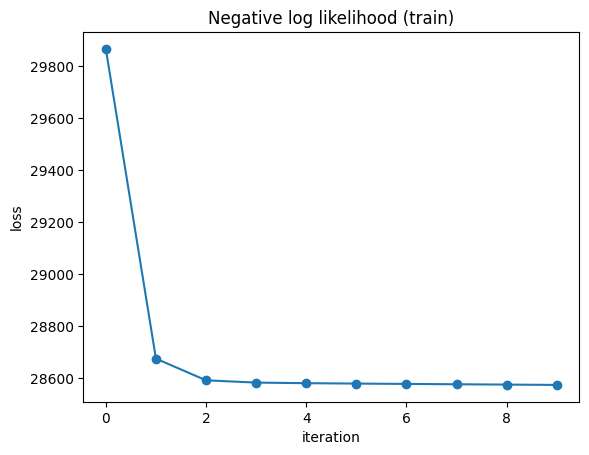

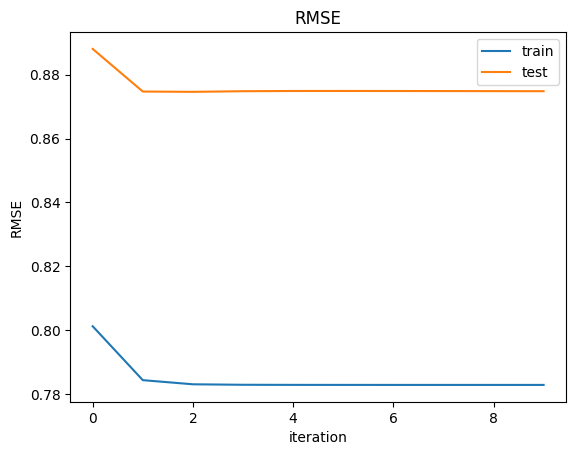

Final RMSE  train: 0.7829   test: 0.8748


In [39]:
def plot(losses, train_rmse, test_rmse):
  plt.plot(losses, marker='o')
  plt.title('Negative log likelihood (train)')
  plt.xlabel('iteration')
  plt.ylabel('loss')
  plt.show()

  plt.plot(train_rmse, label='train')
  plt.plot(test_rmse, label='test')
  plt.title('RMSE')
  plt.xlabel('iteration')
  plt.ylabel('RMSE')
  plt.legend()
  plt.show()
  print(f"Final RMSE  train: {train_rmse[-1]:.4f}   test: {test_rmse[-1]:.4f}")

plot(losses, train_rmse, test_rmse)

## Pratical 3

In [40]:
def squared_error(user_items, user_ratings, U, V, user_biases, item_biases):
  se, count = 0.0, 0
  for m in range(ratings.n_users):
    items, r = user_items[m], user_ratings[m]
    if len(items) == 0:
      continue
    pred = V[items] @ U[m] + user_biases[m] + item_biases[items]
    se += np.sum((r - pred)**2)
    count += len(items)
  return se, count

def loss_fn(U, V, user_biases, item_biases, lda, gamma, tau):
  se, _ = squared_error(user_items_train, user_ratings_train, U, V, user_biases, item_biases)
  reg_1 = (gamma / 2) * (np.sum(U**2) + np.sum(V**2))
  reg_2 = (tau / 2) * (np.sum(user_biases**2) + np.sum(item_biases**2))
  loss = ((lda / 2) * se ) + reg_1 + reg_2
  return loss

def rmse(user_items, user_ratings, U, V, user_biases, item_biases):
  se, count = squared_error(user_items, user_ratings, U, V, user_biases, item_biases)
  return np.sqrt(se / count)

In [41]:
def update_users(U, V, user_biases, item_biases, lda, gamma, tau):
  K = U.shape[1]
  for m in range(ratings.n_users):
    items, r = user_items_train[m], user_ratings_train[m]
    if len(items) == 0:
      continue
    Vm = V[items]

    res = r - Vm @ U[m] - item_biases[items]
    user_biases[m] = lda * np.sum(res) / (lda * len(items) + gamma)

    A = lda * Vm.T @ Vm + (tau * np.eye(K))
    b = lda * Vm.T @ (r - user_biases[m] - item_biases[items])
    U[m] = np.linalg.solve(A, b)

def update_items(U, V, user_biases, item_biases, lda, gamma, tau):
  K = V.shape[1]
  for n in range(ratings.n_items):
    users, r = item_users_train[n], item_ratings_train[n]
    if len(users) == 0:
      item_biases[n] = 0.0
      V[n] = 0.0
      continue
    Un = U[users]

    res = r - Un @ V[n] - user_biases[users]
    item_biases[n] = lda * np.sum(res) / (lda * len(users) + gamma)

    A = lda * Un.T @ Un + (tau * np.eye(K))
    b = lda * Un.T @ (r - user_biases[users] - item_biases[n])
    V[n] = np.linalg.solve(A, b)

In [45]:
def train(K=10, lda=1.0, gamma=0.1, tau=5.0, iterations=20, seed=0):
  rng = np.random.default_rng(seed)
  U = rng.normal(0.1, np.sqrt(max(K, 1)), size=(ratings.n_users, K))
  V = rng.normal(0.1, np.sqrt(max(K, 1)), size=(ratings.n_items, K))
  user_biases = np.zeros(ratings.n_users)
  item_biases = np.zeros(ratings.n_items)

  losses, rmse_train, rmse_test = [], [], []
  for it in tqdm(range(iterations)):
    update_users(U, V, user_biases, item_biases, lda, gamma, tau)
    update_items(U, V, user_biases, item_biases, lda, gamma, tau)

    losses.append(loss_fn(U, V, user_biases, item_biases, lda, gamma, tau))
    rmse_train.append(rmse(user_items_train, user_ratings_train, U, V, user_biases, item_biases))
    rmse_test.append(rmse(user_items_test, user_ratings_test, U, V, user_biases, item_biases))

  return (U, V, user_biases, item_biases), losses, rmse_train, rmse_test

model, losses_r, train_rmse_r, test_rmse_r = train(K=10, lda=1.0, gamma=0.1, tau=5.0, iterations=20)

  0%|          | 0/20 [00:00<?, ?it/s]

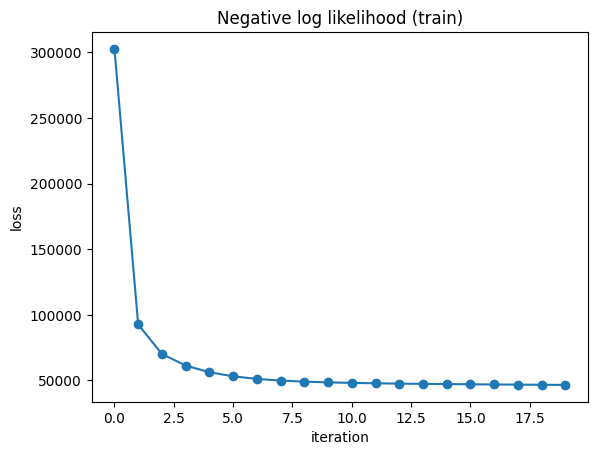

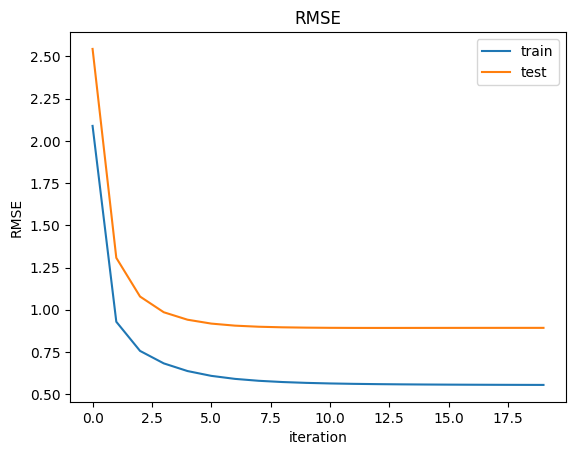

Final RMSE  train: 0.5549   test: 0.8929


In [46]:
plot(losses, train_rmse_r, test_rmse_r)

## Pratical 4

In [ ]:
DATA_DIR = '/content/drive/MyDrive/ml-32m'